# CycleGAN "defect removal" for reconstruction-based anomaly detection

**Idea.** Train an image-to-image translation network that maps a *defective* surface image to its *defect-free*
version. At test time every image is passed through the generator; normal images come back almost unchanged,
while defective ones are "repaired", so the similarity between input and output (SSIM / PSNR / MSE) is an anomaly
score.

**Pipeline**
1. **Synthetic defects** (`make_synthetic_defects.py`): dark dots and short line segments are drawn on defect-free
   line-scan images inside the bright stripe of interest, producing aligned *(clean | defective)* training pairs.
2. **Training**: [pytorch-CycleGAN-and-pix2pix](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix)
   CycleGAN, grayscale 128×128, aligned dataset mode, direction defective→clean, 100 + 100 (decay) epochs.
3. **Scoring**: SSIM and PSNR between each real test image and its translation; ROC/AUROC and the Youden-J optimal
   threshold are computed separately for *spot* defects and *line* defects (100 test images per class).
4. **Two-feature classifier**: an RBF-SVM on standardised (PSNR, SSIM) features.

**Data:** proprietary line-scan images (not included). Only plots and metrics are kept in the outputs.


In [ ]:
!git clone https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix

In [ ]:
import os
os.chdir('pytorch-CycleGAN-and-pix2pix/')

# Root folder of the dataset(s) used in this notebook.
# Set the DATA_ROOT environment variable or edit the default below.
# On Google Colab you can first mount Drive with:
#   from google.colab import drive; drive.mount('/content/drive')
DATA_ROOT = os.environ.get("DATA_ROOT", "./data")

In [ ]:
%pip install -q -r requirements.txt scikit-image scikit-learn pandas opencv-python

## Training

Aligned *(defective | clean)* pairs, grayscale, 128×128, no random crop/resize (`--preprocess none`).

In [ ]:
!python train.py --dataroot {DATA_ROOT}/cyclegan_defects/train_pairs --checkpoints_dir {DATA_ROOT}/cyclegan_defects/checkpoints --name defect_removal --model cycle_gan --no_dropout --dataset_mode aligned --direction BtoA --preprocess none --input_nc 1 --output_nc 1 --load_size 128 --crop_size 128 --display_id -1  --n_epochs 100 --n_epochs_decay 100 --batch_size 16

## Translation of the test sets

Each test folder (`good`, `bad`) is translated with the trained generator; `test.py` writes `*_real.png` /
`*_fake.png` pairs that are compared below.

In [ ]:
!python test.py --dataroot {DATA_ROOT}/cyclegan_defects/bad --checkpoints_dir {DATA_ROOT}/cyclegan_defects/checkpoints --results_dir {DATA_ROOT}/cyclegan_defects/result/bad --name defect_removal --model test --no_dropout --preprocess none --input_nc 1 --output_nc 1 --load_size 128 --crop_size 128 --gpu_ids -1 --num_test 100

## Anomaly scores from input/translation similarity

### Baseline: MSE inside the stripe of interest (spot defects)

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from sklearn.metrics import roc_curve, auc, accuracy_score
import matplotlib.pyplot as plt

def analyze_image_pairs_mse(root_dirs):
    """
    Calculates pixel differences, processes image pairs, and computes ROC curve and accuracy.

    Args:
        root_dirs (list): List of paths to the 'good' and 'bad' image directories.

    Returns:
        tuple: (roc_auc, optimal_threshold, accuracy)
    """
    data = []
    for i, root_dir in enumerate(root_dirs):
        label = i  # Assign 0 to first dir, 1 to second dir
        for filename in os.listdir(root_dir):
            if filename.endswith("_real.png"):
                real_path = os.path.join(root_dir, filename)
                fake_path = os.path.join(root_dir, filename.replace("_real", "_fake"))
                if os.path.exists(fake_path):
                    img1 = cv2.imread(real_path, cv2.IMREAD_GRAYSCALE)
                    img2 = cv2.imread(fake_path, cv2.IMREAD_GRAYSCALE)
                    if img1 is not None and img2 is not None:
                        # Calculate MSE
                        # cast before subtracting: uint8 arithmetic would wrap around
                        mse = np.mean((img1[60:70, :].astype(np.float32) - img2[60:70, :].astype(np.float32))**2)
                        data.append([filename, mse, label])
                    else:
                        print(f"Error: Could not read one or both images: {real_path}, {fake_path}")

    df = pd.DataFrame(data, columns=["filename", "pixel_difference", "class"])
    y_true = df['class'].values
    y_scores = df['pixel_difference'].values
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    j_statistic = tpr - fpr
    optimal_idx = np.argmax(j_statistic)
    optimal_threshold = thresholds[optimal_idx]
    y_pred = (y_scores > optimal_threshold).astype(int)
    accuracy = accuracy_score(y_true, y_pred)

    # Histogram plotting
    plt.figure(figsize=(10, 6))  # Adjust figure size if needed
    plt.hist(df[df['class'] == 0]['pixel_difference'], bins=50, alpha=0.5, label='Class 0 (Good)')
    plt.hist(df[df['class'] == 1]['pixel_difference'], bins=50, alpha=0.5, label='Class 1 (Bad)')
    plt.xlabel('Pixel Difference (MSE)')
    plt.ylabel('Frequency')
    plt.title('Distribution of Pixel Differences by Class')
    plt.legend(loc='upper right')
    plt.show()
    # Plot the ROC curve (optional)
    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.show()

    return roc_auc, optimal_threshold, accuracy,df

# Example usage

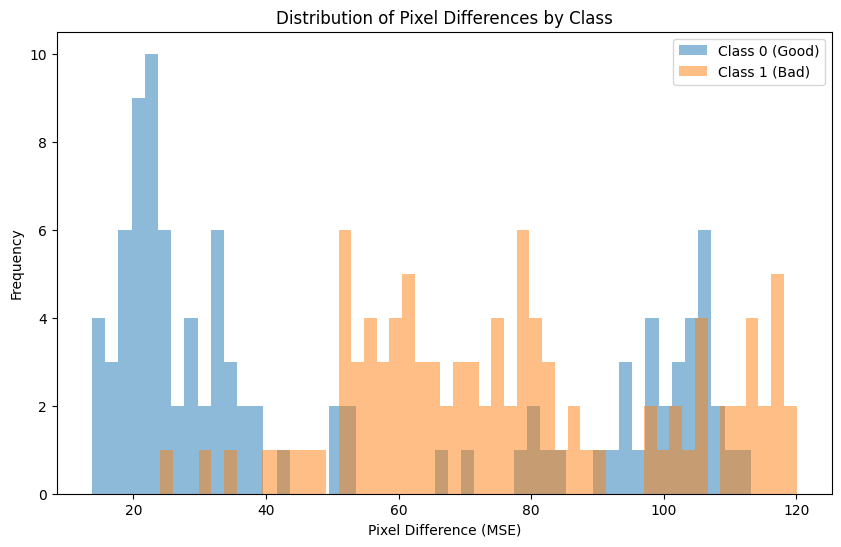

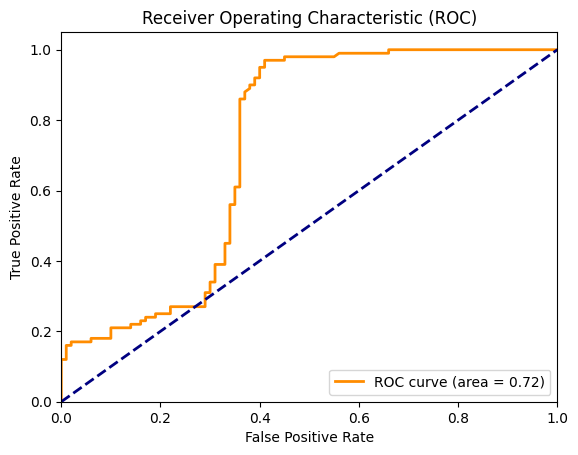

AUROC: 0.7243999999999999
Optimal Threshold: 40.4609375
Accuracy at optimal threshold: 0.775


In [ ]:
root_dirs = [
    f"{DATA_ROOT}/cyclegan_defects/result/good/defect_removal/test_latest/images",
    f"{DATA_ROOT}/cyclegan_defects/result/bad/defect_removal/test_latest/images"
]

roc_auc, optimal_threshold, accuracy,df = analyze_image_pairs_mse(root_dirs)
print(f"AUROC: {roc_auc}")
print(f"Optimal Threshold: {optimal_threshold}")
print(f"Accuracy at optimal threshold: {accuracy}")

### SSIM and PSNR (spot defects)

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from sklearn.metrics import roc_curve, auc, accuracy_score
import matplotlib.pyplot as plt

def analyze_image_pairs(root_dirs):
    """
    Calculates image differences using MSE, SSIM, and PSNR, processes image pairs,
    and computes ROC curve and accuracy for each metric.

    Args:
        root_dirs (list): List of paths to the 'good' and 'bad' image directories.

    Returns:
        tuple: (results_df, roc_auc_dict, optimal_threshold_dict, accuracy_dict)
    """
    data = []
    for i, root_dir in enumerate(root_dirs):
        label = 1-i  # Assign 0 to first dir, 1 to second dir
        for filename in os.listdir(root_dir):
            if filename.endswith("_real.png"):
                real_path = os.path.join(root_dir, filename)
                fake_path = os.path.join(root_dir, filename.replace("_real", "_fake"))
                if os.path.exists(fake_path):
                    img1 = cv2.imread(real_path, cv2.IMREAD_GRAYSCALE)
                    img2 = cv2.imread(fake_path, cv2.IMREAD_GRAYSCALE)
                    if img1 is not None and img2 is not None:
                        # Calculate MSE
                        # cast before subtracting: uint8 arithmetic would wrap around
                        mse = np.mean((img1[60:70, :].astype(np.float32) - img2[60:70, :].astype(np.float32))**2)
                        # Calculate SSIM
                        ssim_score = ssim(img1, img2)
                        # Calculate PSNR
                        psnr_score = psnr(img1, img2, data_range=255)
                        data.append([filename, mse, ssim_score, psnr_score, label])
                    else:
                        print(f"Error: Could not read one or both images: {real_path}, {fake_path}")

    df = pd.DataFrame(data, columns=["filename", "mse", "ssim", "psnr", "class"])

    results_df = df.copy()  # Store the dataframe with all metrics
    roc_auc_dict = {}
    optimal_threshold_dict = {}
    accuracy_dict = {}

    for metric in ["ssim", "psnr"]:
        y_true = df['class'].values
        y_scores = df[metric].values
        fpr, tpr, thresholds = roc_curve(y_true, y_scores)
        roc_auc = auc(fpr, tpr)
        j_statistic = tpr - fpr
        optimal_idx = np.argmax(j_statistic)
        optimal_threshold = thresholds[optimal_idx]

        y_pred = (y_scores > optimal_threshold).astype(int)
        accuracy = accuracy_score(y_true, y_pred)

        roc_auc_dict[metric] = roc_auc
        optimal_threshold_dict[metric] = optimal_threshold
        accuracy_dict[metric] = accuracy

        # Histogram plotting for each metric
        plt.figure(figsize=(10, 6))
        plt.hist(df[df['class'] == 0][metric], bins=50, alpha=0.5, label='Class 0 (bad)')
        plt.hist(df[df['class'] == 1][metric], bins=50, alpha=0.5, label='Class 1 (good)')
        plt.xlabel(f'{metric.upper()} Value')
        plt.ylabel('Frequency')
        plt.title(f'Distribution of {metric.upper()} by Class')
        plt.legend(loc='upper right')
        plt.show()

        # Plot the ROC curve for each metric
        plt.figure()
        plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
        plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
        plt.xlim([0.0, 1.0])
        plt.ylim([0.0, 1.05])
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title(f'Receiver Operating Characteristic (ROC) - {metric.upper()}')
        plt.legend(loc="lower right")
        plt.show()
        plt.figure(figsize=(10, 6))
        plt.scatter(df[df['class'] == 0]['mse'], df[df['class'] == 0]['ssim'], alpha=0.5, label='Class 0 (bad)', marker='o')  # Class 0 with circles
        plt.scatter(df[df['class'] == 1]['mse'], df[df['class'] == 1]['ssim'], alpha=0.5, label='Class 1 (good)', marker='x') # Class 1 with x's
        plt.xlabel('MSE Value')
        plt.ylabel('SSIM Value')
        plt.title('Scatter Plot of MSE vs. SSIM by Class')
        plt.legend(loc='upper right')
        plt.show()
    return results_df, roc_auc_dict, optimal_threshold_dict, accuracy_dict

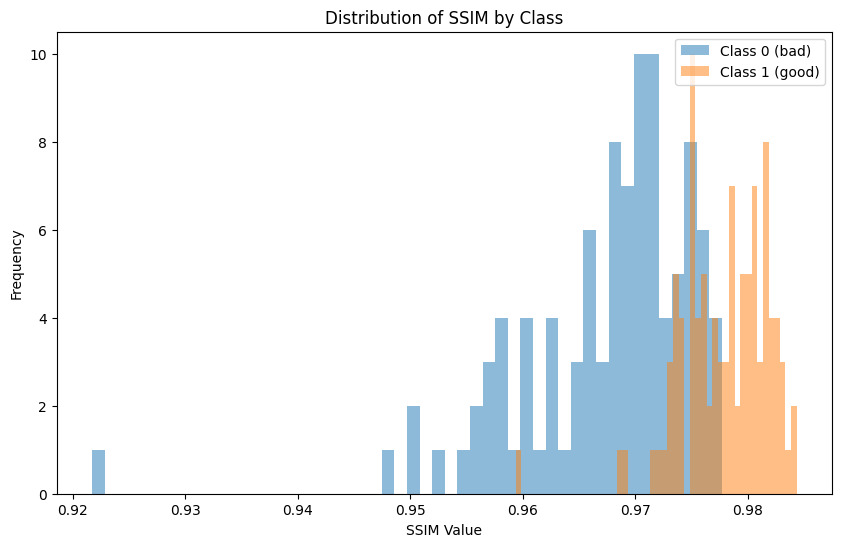

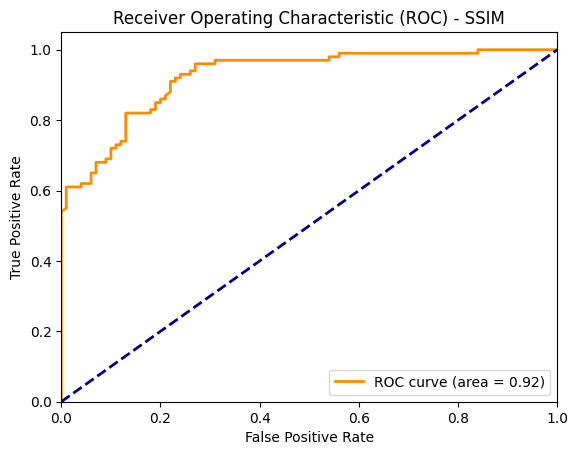

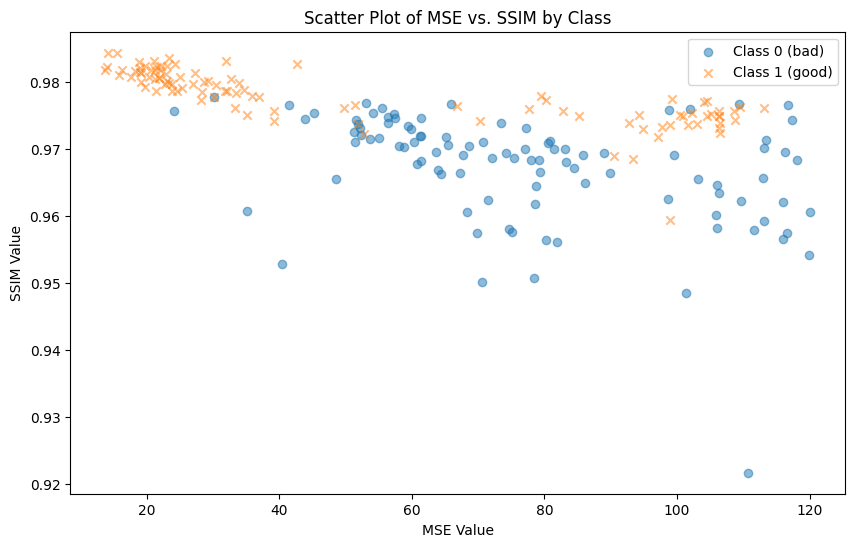

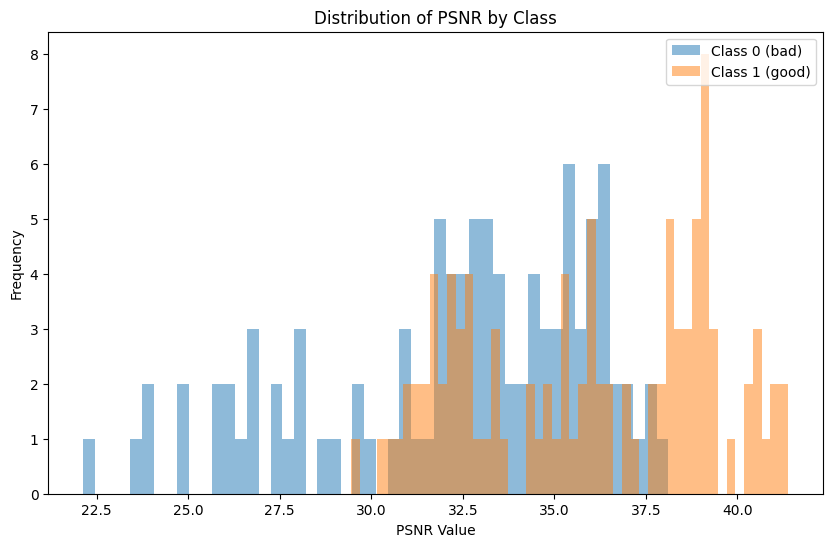

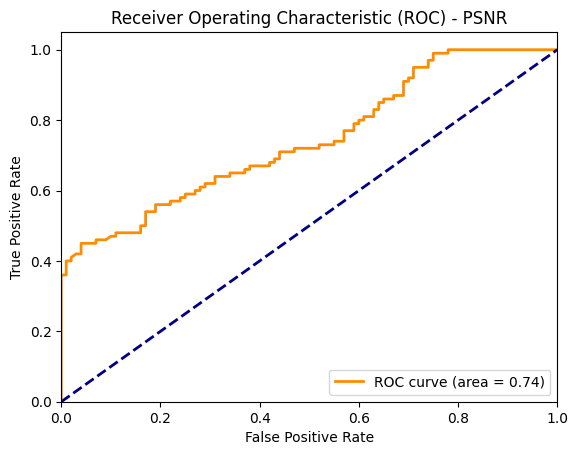

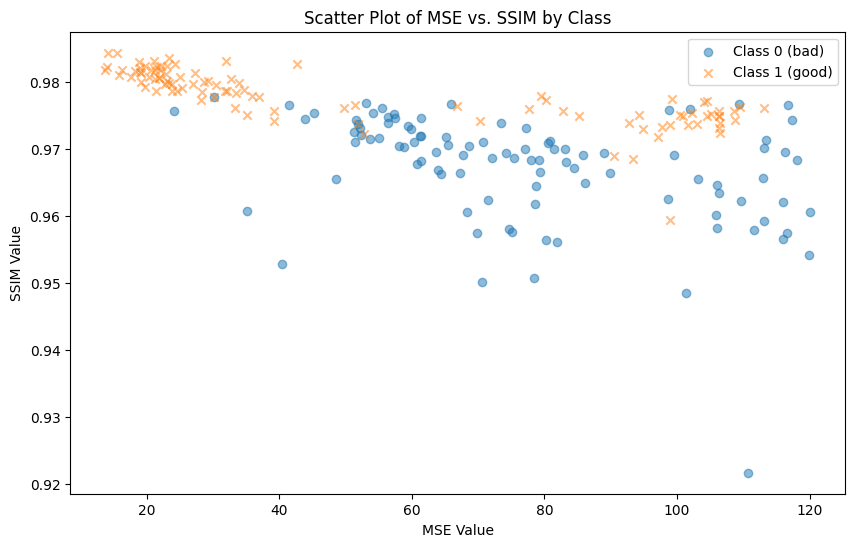

AUROC (SSIM): 0.9248
AUROC (PSNR): 0.743
Accuracy (SSIM): 0.84
Accuracy (PSNR): 0.7
Optimal Threshold (SSIM): 0.9735639583656185
Optimal Threshold (PSNR): 36.95904987466791


In [ ]:
root_dirs = [
    f"{DATA_ROOT}/cyclegan_defects/result/good/defect_removal/test_latest/images",
    f"{DATA_ROOT}/cyclegan_defects/result/bad/defect_removal/test_latest/images"
]

results_df, roc_auc_dict, optimal_threshold_dict, accuracy_dict = analyze_image_pairs(root_dirs)
print(f"AUROC (SSIM): {roc_auc_dict['ssim']}")
print(f"AUROC (PSNR): {roc_auc_dict['psnr']}")

print(f"Accuracy (SSIM): {accuracy_dict['ssim']}")
print(f"Accuracy (PSNR): {accuracy_dict['psnr']}")

print(f"Optimal Threshold (SSIM): {optimal_threshold_dict['ssim']}")
print(f"Optimal Threshold (PSNR): {optimal_threshold_dict['psnr']}")

### Line defects

In [ ]:
!python test.py --dataroot {DATA_ROOT}/cyclegan_defects/withline/good --checkpoints_dir {DATA_ROOT}/cyclegan_defects/checkpoints --results_dir {DATA_ROOT}/cyclegan_defects/resultline/good --name defect_removal --model test --no_dropout --preprocess none --input_nc 1 --output_nc 1 --load_size 128 --crop_size 128 --gpu_ids -1 --num_test 100

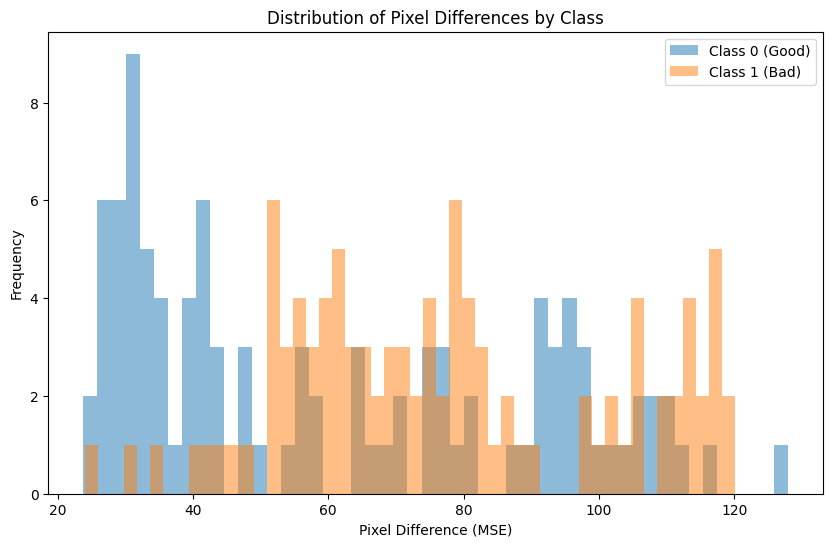

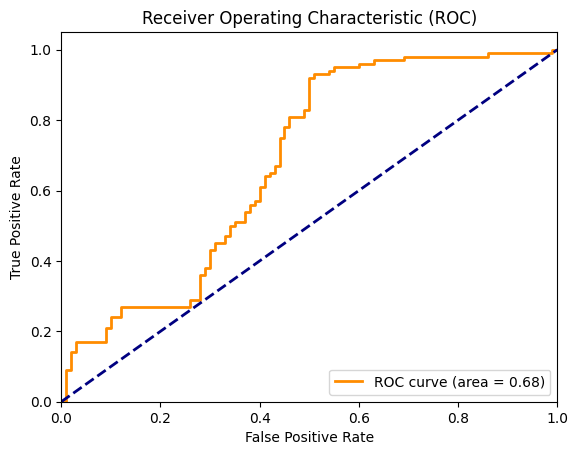

AUROC: 0.6802
Optimal Threshold: 51.20234375
Accuracy at optimal threshold: 0.705


In [ ]:
root_dirs = [
    f"{DATA_ROOT}/cyclegan_defects/resultline/good/defect_removal/test_latest/images",
    f"{DATA_ROOT}/cyclegan_defects/resultline/bad/defect_removal/test_latest/images"
]

roc_auc, optimal_threshold, accuracy,df = analyze_image_pairs_mse(root_dirs)
print(f"AUROC: {roc_auc}")
print(f"Optimal Threshold: {optimal_threshold}")
print(f"Accuracy at optimal threshold: {accuracy}")

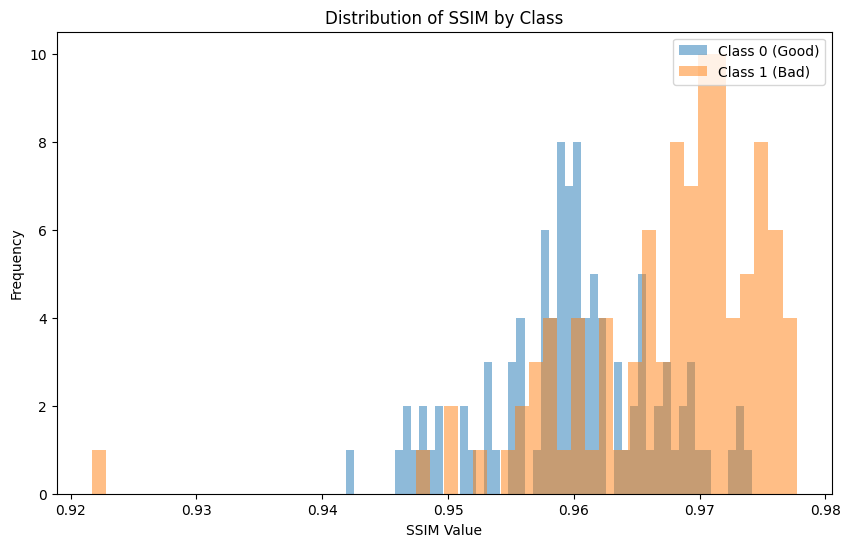

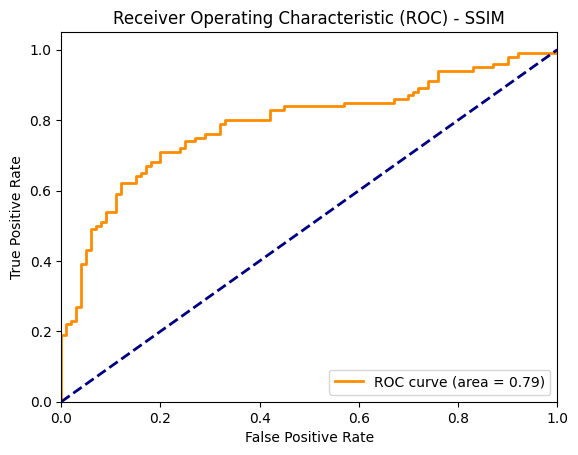

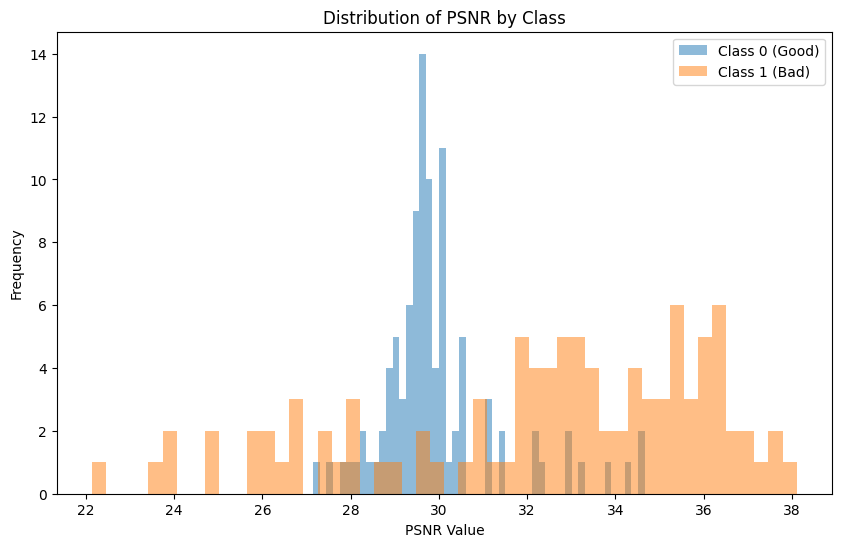

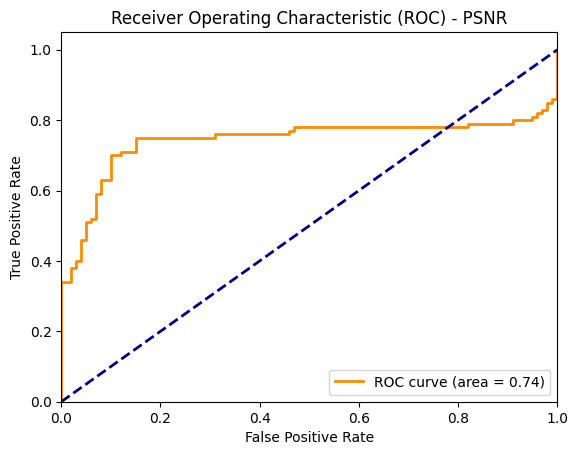

AUROC (SSIM): 0.7903
AUROC (PSNR): 0.7428
Accuracy (SSIM): 0.75
Accuracy (PSNR): 0.795


In [ ]:
root_dirs = [
    f"{DATA_ROOT}/cyclegan_defects/resultline/good/defect_removal/test_latest/images",
    f"{DATA_ROOT}/cyclegan_defects/resultline/bad/defect_removal/test_latest/images"
]

results_df, roc_auc_dict, optimal_threshold_dict, accuracy_dict = analyze_image_pairs(root_dirs)
print(f"AUROC (SSIM): {roc_auc_dict['ssim']}")
print(f"AUROC (PSNR): {roc_auc_dict['psnr']}")

print(f"Accuracy (SSIM): {accuracy_dict['ssim']}")
print(f"Accuracy (PSNR): {accuracy_dict['psnr']}")

### Combining PSNR (line run) and SSIM (spot run) per file

Exploratory: the two runs share file names, so their scores are joined per image and a small RBF-SVM is trained on half of the samples and evaluated on the other half.

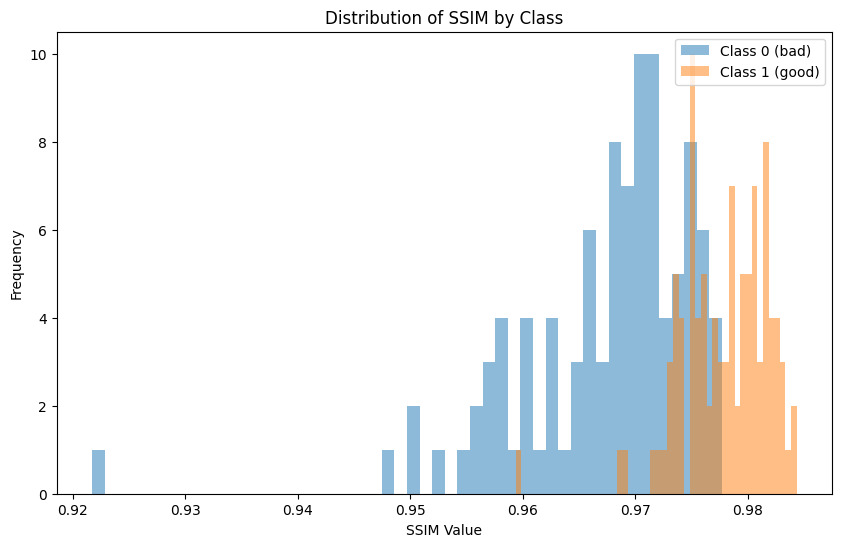

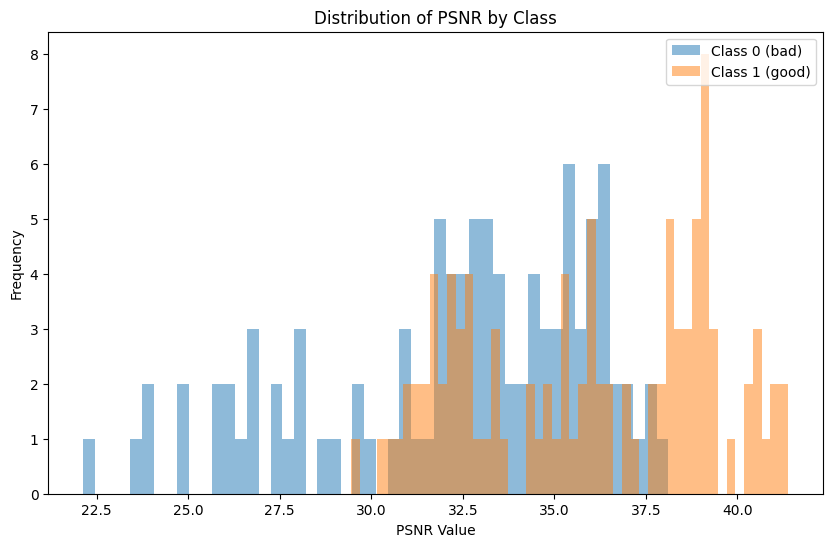

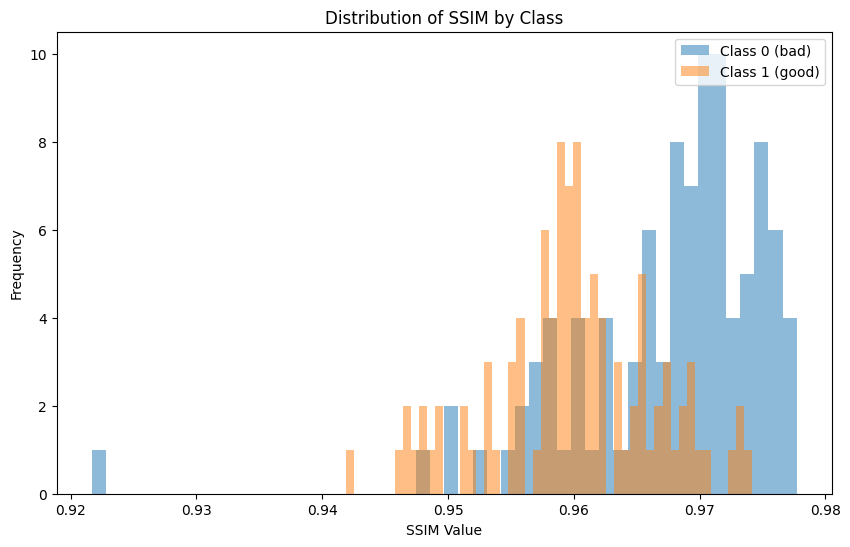

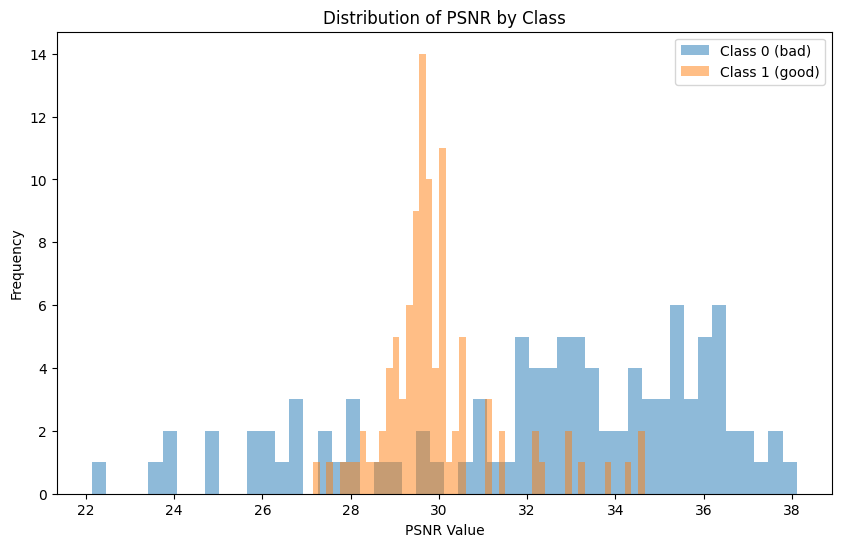

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import peak_signal_noise_ratio as psnr
from sklearn.metrics import roc_curve, auc, accuracy_score
import matplotlib.pyplot as plt

def analyze_image_pairs(root_dirs, label_type):
    """
    Calculates image differences using MSE, SSIM, and PSNR, processes image pairs,
    and computes ROC curve and accuracy for each metric.

    Args:
        root_dirs (list): List of paths to the 'good' and 'bad' image directories.
        label_type (str): 'inverted' for label = 1-i, 'normal' for label = i

    Returns:
        tuple: (results_df, roc_auc_dict, optimal_threshold_dict, accuracy_dict)
    """
    data = []
    for i, root_dir in enumerate(root_dirs):
        if label_type == 'normal':
            label = 1 - i  # Assign 0 to first dir, 1 to second dir
        elif label_type == 'inverted':
            label = i  # Assign 0 to first dir, 1 to second dir
        else:
            raise ValueError("Invalid label_type. Choose 'inverted' or 'normal'.")

        for filename in os.listdir(root_dir):
            if filename.endswith("_real.png"):  # Only process "real" images

                real_path = os.path.join(root_dir, filename)
                fake_path = os.path.join(root_dir, filename.replace("_real", "_fake"))

                if os.path.exists(fake_path):
                    img1 = cv2.imread(real_path, cv2.IMREAD_GRAYSCALE)
                    img2 = cv2.imread(fake_path, cv2.IMREAD_GRAYSCALE)
                    if img1 is not None and img2 is not None:
                        # Calculate MSE
                        # cast before subtracting: uint8 arithmetic would wrap around
                        mse = np.mean((img1[60:70, :].astype(np.float32) - img2[60:70, :].astype(np.float32))**2)
                        # Calculate SSIM
                        ssim_score = ssim(img1, img2)
                        # Calculate PSNR
                        psnr_score = psnr(img1, img2, data_range=255)
                        data.append([filename, mse, ssim_score, psnr_score, label])
                    else:
                        print(f"Error: Could not read one or both images: {real_path}, {fake_path}")
            else:  # Skip files that are not "real" images
                continue
    df = pd.DataFrame(data, columns=["filename", "mse", "ssim", "psnr", "class"])

    results_df = df.copy()  # Store the dataframe with all metrics
    roc_auc_dict = {}
    optimal_threshold_dict = {}
    accuracy_dict = {}

    for metric in ["ssim", "psnr"]:
        y_true = df['class'].values
        y_scores = df[metric].values
        fpr, tpr, thresholds = roc_curve(y_true, y_scores)
        roc_auc = auc(fpr, tpr)
        j_statistic = tpr - fpr
        optimal_idx = np.argmax(j_statistic)
        optimal_threshold = thresholds[optimal_idx]

        y_pred = (y_scores > optimal_threshold).astype(int)
        accuracy = accuracy_score(y_true, y_pred)

        roc_auc_dict[metric] = roc_auc
        optimal_threshold_dict[metric] = optimal_threshold
        accuracy_dict[metric] = accuracy

        # Histogram plotting for each metric
        plt.figure(figsize=(10, 6))
        plt.hist(df[df['class'] == 0][metric], bins=50, alpha=0.5, label='Class 0 (bad)')
        plt.hist(df[df['class'] == 1][metric], bins=50, alpha=0.5, label='Class 1 (good)')
        plt.xlabel(f'{metric.upper()} Value')
        plt.ylabel('Frequency')
        plt.title(f'Distribution of {metric.upper()} by Class')
        plt.legend(loc='upper right')
        plt.show()

        # Plot the ROC curve for each metric

    return results_df, roc_auc_dict, optimal_threshold_dict, accuracy_dict,df

# 1. Execute analyze_image_pairs twice, storing results
root_dirs1 = [
    f"{DATA_ROOT}/cyclegan_defects/result/good/defect_removal/test_latest/images",
    f"{DATA_ROOT}/cyclegan_defects/result/bad/defect_removal/test_latest/images"
]
root_dirs2 = [
    f"{DATA_ROOT}/cyclegan_defects/resultline/good/defect_removal/test_latest/images",
    f"{DATA_ROOT}/cyclegan_defects/resultline/bad/defect_removal/test_latest/images"
]

# First execution with label = 1-i
results_df1, _, _, _,df1 = analyze_image_pairs(root_dirs1, label_type='normal')
ssim_values1 = df1['ssim'].values  # SSIM values for class 1 (good)

# Second run on the line-defect results
results_df2, _, _, _,df2 = analyze_image_pairs(root_dirs2, label_type='normal')
psnr_values2 = df2['psnr'].values

In [ ]:
num_rows = len(df1)
print(f"Number of data points in df: {num_rows}")

Number of data points in df: 200


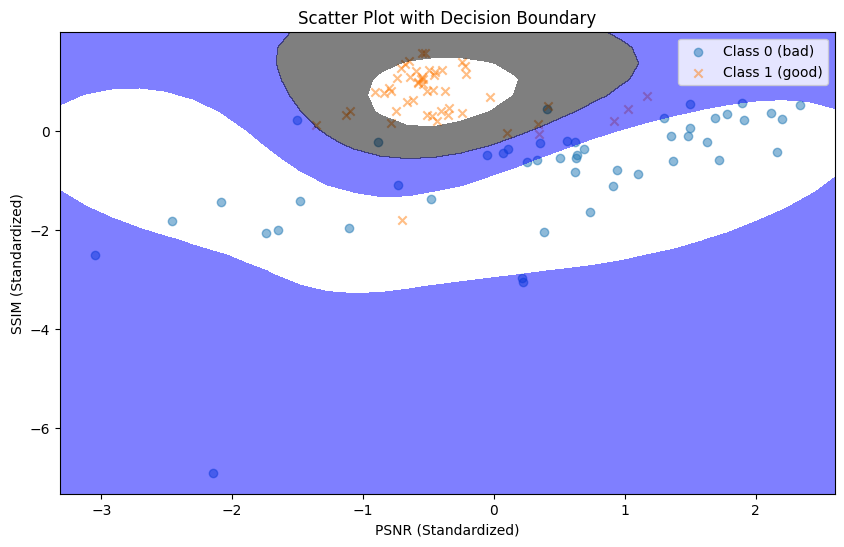

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split

# 1. Join the two runs on the file name (PSNR from the line-defect run, SSIM from the spot-defect run).
#    Note: the logged accuracy below was produced by an earlier version that stacked the two columns
#    positionally; joining on the file name is the correct way to pair the features.
merged = df1.merge(df2[['filename', 'class', 'psnr']], on=['filename', 'class'], suffixes=('_spot', '_line'))
X = merged[['psnr_line', 'ssim']].values  # Features (PSNR, SSIM)
y = merged['class'].values  # Target variable (class labels)

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=42)

# 3. Feature Scaling (Standardization)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Train the model (RBF kernel SVM)
model = SVC(kernel='rbf', C=1.0, gamma='scale')  # Adjust C and gamma if needed
model.fit(X_train, y_train)

# 5. Create the scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(X_test[y_test== 0, 0], X_test[y_test == 0, 1],
            alpha=0.5, label='Class 0 (bad)', marker='o')
plt.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
            alpha=0.5, label='Class 1 (good)', marker='x')
plt.xlabel('PSNR (Standardized)')
plt.ylabel('SSIM (Standardized)')
plt.title('Scatter Plot with Decision Boundary')
plt.legend()

## Plot decision boundary using a filled contour
ax = plt.gca() # Get current axes
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Create grid to evaluate model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = model.decision_function(xy).reshape(XX.shape)

# Plot decision boundary and margins
ax.contourf(XX, YY, Z, levels=[-1, 0, 1], alpha=0.5,
           colors=['blue', 'k', 'red'])  # Customize colors as needed

plt.show()

In [ ]:
y_pred = model.predict(X_test)  # X_test contains the PSNR and SSIM values of your test data
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy on test data: {accuracy}")

Accuracy on test data: 0.93
